# Graphite crust on Mercury

In [28]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, LogNorm, Normalize, SymLogNorm
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import matplotlib.patheffects as pe
import cmcrameri.cm as cmc
from copy import deepcopy

import utils.load_grid as lg
from proteus.utils.constants import (CONDENSATE_SATURATED_ACTIVITY, condensate_conductivity,
                                     condensate_density)
from proteus.utils.helper import CommentFromStatus

In [2]:
pgrid_dir = "data/scratch/mercury_graphite_grid_v16"
outdir = os.path.join("output", os.path.basename(pgrid_dir) + "_analysis")
os.makedirs(outdir, exist_ok=True)

SATURATED = CONDENSATE_SATURATED_ACTIVITY   # activity at and above which graphite counts as saturated
CRUST_MIN_M = 1e-3                          # thinner graphite layers count as no crust [m]
RHO_GRAPHITE = condensate_density["C"]      # [kg m-3]
K_GRAPHITE = condensate_conductivity["C"]   # [W m-1 K-1]
STATUS_ESCAPED = 15                         # run stopped because the atmosphere escaped

# Mercury's present-day surface fO2 relative to IW (Sossi review)
MERCURY_DIW, MERCURY_DIW_ERR = -5.0, 0.4

# Low-reflectance material: initial crustal thickness, and its graphite equivalent [m]
LRM_CRUST_M = 4300.0
LRM_GRAPHITE_M = 120.0

In [3]:
cases = lg.get_cases(pgrid_dir, only_completed=True)
cfgs = lg.load_configs(cases)
helps, _ = lg.load_helpfiles(cases)

def cfg_array(key, dtype=float):
    return np.array(lg.access_configs(cfgs, key), dtype=dtype)

dIW = cfg_array("outgas.fO2_shift_IW")
Cb = cfg_array("planet.elements.C_budget")
cond = cfg_array("outgas.atmodeller.include_condensates", bool)
eta = cfg_array("escape.zephyrus.efficiency")
status = np.array([lg.get_status(c) for c in cases])

C_mode = lg.access_configs(cfgs, "planet.elements.C_mode")[0]
C_label = {"ppmw": "C [ppmw of mantle]", "C/H": "C/H mass ratio", "kg": "C [kg]"}.get(C_mode, "C budget")

ETA_OFF, ETA_ON = np.unique(eta)   # escape efficiency of the off and on arms
ESC_LABEL = {ETA_OFF: "Escape off", ETA_ON: rf"Escape on ($\eta$ = {ETA_ON:g})"}
SAT_LABEL = {True: "Saturation on", False: "Saturation off"}

print(f"{len(cases)} completed cases; carbon given as {C_mode}")
pd.crosstab([pd.Series(cond, name="saturation"), pd.Series(eta, name="escape eff.")],
            pd.Series([CommentFromStatus(s) for s in status], name="stop reason"))

Configs:   0%|          | 0/120 [00:00<?, ?it/s]outgas.prevent_desaturation = true has no effect with outgas.atmodeller.include_condensates = false
atmos_clim.surface_d = 'saturation' keeps the surface fixed with outgas.atmodeller.include_condensates = false


Atmodeller initialized with double precision (float64)


Configs:   1%|          | 1/120 [00:03<07:51,  3.96s/it]outgas.prevent_desaturation = true has no effect with outgas.atmodeller.include_condensates = false
atmos_clim.surface_d = 'saturation' keeps the surface fixed with outgas.atmodeller.include_condensates = false
outgas.prevent_desaturation = true has no effect with outgas.atmodeller.include_condensates = false
atmos_clim.surface_d = 'saturation' keeps the surface fixed with outgas.atmodeller.include_condensates = false
outgas.prevent_desaturation = true has no effect with outgas.atmodeller.include_condensates = false
atmos_clim.surface_d = 'saturation' keeps the surface fixed with outgas.atmodeller.include_condensates = false
outgas.prevent_desaturation = true has no effect with outgas.atmodeller.include_condensates = false
atmos_clim.surface_d = 'saturation' keeps the surface fixed with outgas.atmodeller.include_condensates = false
outgas.prevent_desaturation = true has no effect with outgas.atmodeller.include_condensates = false


120 completed cases; carbon given as ppmw


stop reason             Completed (net flux is small)  Completed (solidified)  \
saturation escape eff.                                                          
False      0.0                                      0                      30   
           0.1                                      3                      24   
True       0.0                                      0                      30   
           0.1                                      3                      21   

stop reason             Completed (volatiles escaped)  
saturation escape eff.                                 
False      0.0                                      0  
           0.1                                      3  
True       0.0                                      0  
           0.1                                      6

In [4]:
COLS = ["Time", "C_cd_activity", "C_cd_kg", "R_int", "T_magma", "T_surf", "F_int", "F_atm",
        "Phi_global", "P_surf", "boundary_layer_thickness", "boundary_layer_conductivity",
        "C_kg_atm", "C_kg_condensed", "CO_bar", "atm_converged"]

rows, series = [], {}
for case, hf, x, y, on, e, s in zip(cases, helps, dIW, Cb, cond, eta, status):
    ts = {k: np.array(hf[k], dtype=float) for k in COLS}
    ts["thick"] = ts["C_cd_kg"] / (4.0 * np.pi * ts["R_int"] ** 2) / RHO_GRAPHITE  # [m]
    ts["dT_skin"] = ts["T_magma"] - ts["T_surf"]                                     # [K]
    series[(x, y, on, e)] = ts

    sat = np.flatnonzero(ts["C_cd_activity"] >= SATURATED)
    skin = ts["boundary_layer_thickness"] > 0
    rows.append(dict(case=os.path.basename(case), dIW=x, C=y, cond=on, eta=e, status=s,
                     time_end=ts["Time"][-1], T_magma_end=ts["T_magma"][-1],
                     T_surf_end=ts["T_surf"][-1], P_surf_end=ts["P_surf"][-1],
                     act_max=ts["C_cd_activity"].max(), thickness_m=ts["thick"][-1],
                     onset_yr=ts["Time"][sat[0]] if len(sat) else np.nan,
                     dT_skin_end=ts["dT_skin"][-1],
                     dT_skin_max=ts["dT_skin"][skin].max() if skin.any() else 0.0))

summary = pd.DataFrame(rows).sort_values(["cond", "eta", "dIW", "C"]).reset_index(drop=True)
summary.to_csv(os.path.join(outdir, "summary.csv"), index=False)

# Checks: no graphite without saturation, and the skin is the graphite layer where it exists
print("Max graphite thickness with saturation off:",
      summary.loc[~summary["cond"], "thickness_m"].max(), "m")
dev = [np.abs(ts["boundary_layer_thickness"][m] / ts["thick"][m] - 1).max()
       for ts in series.values() if (m := ts["boundary_layer_thickness"] > 0).any()]
print(f"Skin thickness vs graphite layer: max relative difference {max(dev):.1e}")

summary.assign(crust=summary["thickness_m"] > CRUST_MIN_M).groupby(["cond", "eta"])["crust"].sum() \
    .rename("runs with a crust").to_frame()

Max graphite thickness with saturation off: 0.0 m
Skin thickness vs graphite layer: max relative difference 4.4e-16


runs with a crust
cond  eta                   
False 0.0                  0
      0.1                  0
True  0.0                 25
      0.1                  3

In [5]:
# Arrange onto the 2D parameter plane
xs = np.unique(summary["dIW"])
ys = np.unique(summary["C"])

def arm(on, e):
    """Rows of one A/B arm: saturation on/off and escape efficiency e."""
    return summary[(summary["cond"] == on) & (summary["eta"] == e)]

def on_plane(col, df):
    Z = np.full((len(ys), len(xs)), np.nan)
    for _, r in df.iterrows():
        Z[np.searchsorted(ys, r["C"]), np.searchsorted(xs, r["dIW"])] = r[col]
    return Z

def cell_edges(v, log=False):
    """Cell edges halfway between grid values (geometric midpoints on a log axis)."""
    v = np.log10(v) if log else np.asarray(v, dtype=float)
    if len(v) == 1:
        e = np.array([v[0] - 0.5, v[0] + 0.5])
    else:
        mid = 0.5 * (v[1:] + v[:-1])
        e = np.concatenate([[v[0] - (mid[0] - v[0])], mid, [v[-1] + (v[-1] - mid[-1])]])
    return 10 ** e if log else e

x_edges = cell_edges(xs)
y_edges = cell_edges(ys, log=True)

In [6]:
def label(ax, x, y, txt):
    """Cell label with a thin white outline, above the fO2 band."""
    ax.text(x, y, txt, ha="center", va="center", fontsize=8, color='k', zorder=6,
            path_effects=[pe.withStroke(linewidth=2.0, foreground='w')])

def mesh(ax, Z, cmap, norm, fmt, empty, empty_text):
    """Colour mesh of Z with per-cell labels; cells where `empty` is true are grey."""
    ax.pcolormesh(x_edges, y_edges, np.where(empty, 1.0, np.nan), cmap="Greys",
                  vmin=0, vmax=4, shading="flat")
    pm = ax.pcolormesh(x_edges, y_edges, np.ma.masked_where(empty, Z),
                       cmap=cmap, norm=norm, shading="flat")
    for i, y in enumerate(ys):
        for j, x in enumerate(xs):
            if empty[i, j]:
                label(ax, x, y, empty_text)
            elif np.isfinite(Z[i, j]):
                label(ax, x, y, fmt(i, j))
    return pm

def plane_axes(ax, legend=False):
    """Mercury fO2 band and axis labels of a parameter-plane panel."""
    ax.axvspan(MERCURY_DIW - MERCURY_DIW_ERR, MERCURY_DIW + MERCURY_DIW_ERR,
               facecolor="orangered", edgecolor="k", hatch="//", lw=0, alpha=0.3, zorder=2)
    ax.axvline(MERCURY_DIW, color="orangered", ls="solid", lw=1.4, zorder=3,
               label="Surface fO$_2$ (Sossi+25)" if legend else None)
    ax.set_yscale("log")
    ax.set_xlabel(r"$\Delta$IW (fO$_2$ relative to iron-wüstite)")
    ax.set_ylabel(C_label)

def escaped_mark(Zs):
    """Label suffix '*' for runs that stopped because their atmosphere escaped."""
    return lambda i, j: "*" if Zs[i, j] == STATUS_ESCAPED else ""

## Endpoint crust and onset of saturation: escape off and on

Saturation-on runs only: with saturation off no graphite forms (checked above). A `*` marks a run that stopped because its atmosphere escaped (status 15), so its crust is the crust at that time, not at solidification. Both columns share their colour scales.

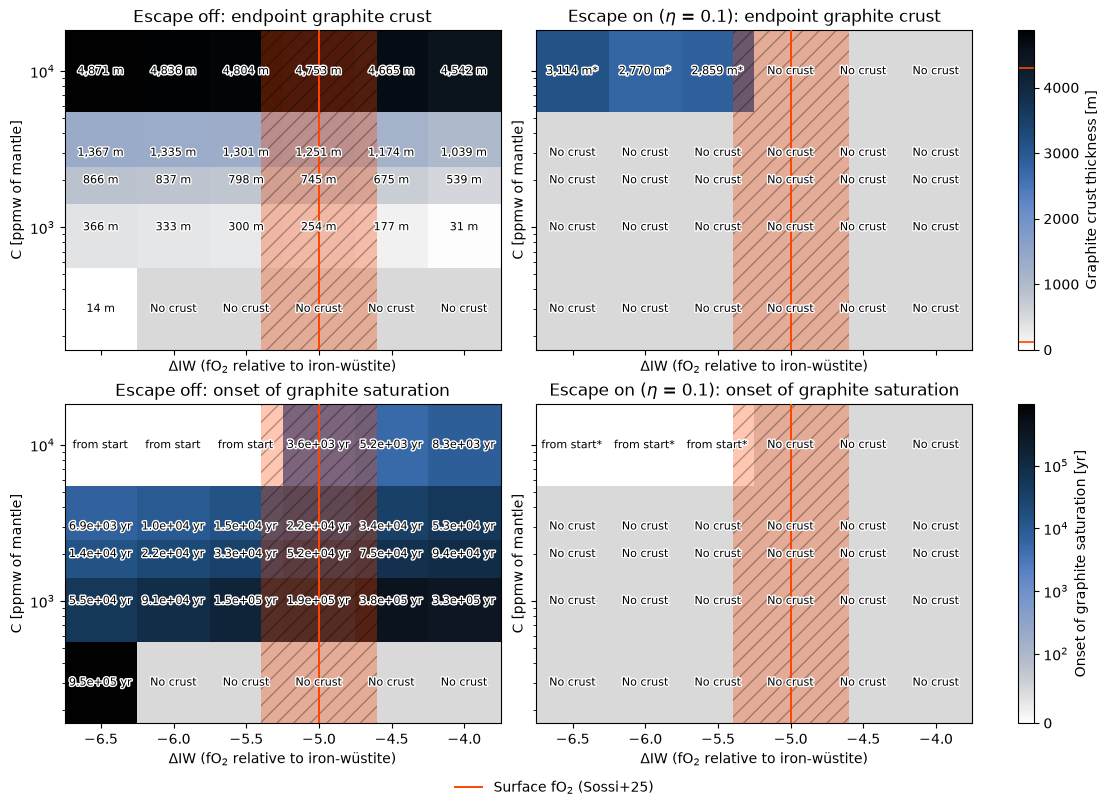

In [7]:
ESC_ARMS = (ETA_OFF, ETA_ON)
Z_t = {e: on_plane("thickness_m", arm(True, e)) for e in ESC_ARMS}
Z_o = {e: on_plane("onset_yr", arm(True, e)) for e in ESC_ARMS}
Z_s = {e: on_plane("status", arm(True, e)) for e in ESC_ARMS}

t_max = max(np.nanmax(Z) for Z in Z_t.values())
o_max = max((np.nanmax(Z) for Z in Z_o.values() if np.isfinite(Z).any()), default=1.0)
norm_t = Normalize(vmin=0, vmax=max(t_max, 1.0))
norm_o = SymLogNorm(vmin=0, vmax=max(o_max, 1.0), linthresh=1e2)

def fmt_onset(v):
    return "from start" if v == 0 else f"{v:.1e} yr"

fig, axs = plt.subplots(2, 2, figsize=(11, 8), sharex=True, sharey=True, layout="constrained")
for j, e in enumerate(ESC_ARMS):
    star = escaped_mark(Z_s[e])
    Zt, Zo = Z_t[e], Z_o[e]
    pm_t = mesh(axs[0, j], Zt, cmc.oslo_r, norm_t, lambda i, k: f"{Zt[i, k]:,.0f} m{star(i, k)}",
                Zt < CRUST_MIN_M, "No crust")
    pm_o = mesh(axs[1, j], Zo, cmc.oslo_r, norm_o, lambda i, k: fmt_onset(Zo[i, k]) + star(i, k),
                np.isnan(Zo), "No crust")
    axs[0, j].set_title(f"{ESC_LABEL[e]}: endpoint graphite crust")
    axs[1, j].set_title(f"{ESC_LABEL[e]}: onset of graphite saturation")
    for ax in axs[:, j]:
        plane_axes(ax, legend=(ax is axs[0, 0]))

cb = fig.colorbar(pm_t, ax=axs[0, :], label="Graphite crust thickness [m]")
for v in (LRM_GRAPHITE_M, LRM_CRUST_M):
    if norm_t.vmin <= v <= norm_t.vmax:
        cb.ax.axhline(v, color="orangered", ls="solid", lw=1.2)
fig.colorbar(pm_o, ax=axs[1, :], label="Onset of graphite saturation [yr]")

fig.legend(loc="outside lower center", ncol=2, frameon=False)
fig.savefig(os.path.join(outdir, "graphite_grid_thickness_onset.pdf"), bbox_inches="tight")
plt.show()

## Graphite crust thickness against time

Saturation-on runs, one panel per carbon budget, one colour per fO$_2$. Solid lines: escape off; dashed lines: escape on. The black lines mark the LRM reference values: the observed initial crustal thickness (4.3 km, dashed) and its graphite equivalent (120 m, dotted). A line starts at the onset of saturation, since the thickness is zero before it. Where the escape-on run follows the escape-off run, its dashed line lies on the solid one.

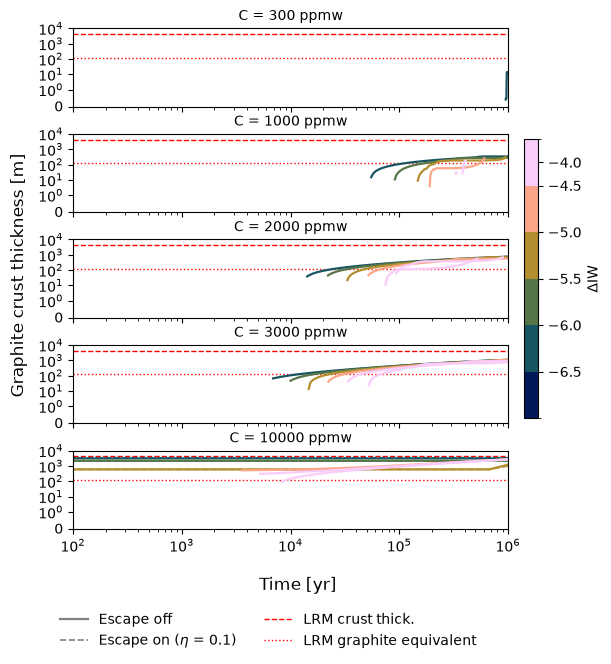

In [20]:
cmap_f = cmc.batlow
norm_f = BoundaryNorm(np.concatenate([xs - 0.5, [xs[-1] + 0.5]]), cmap_f.N)
ESC_LS = {ETA_OFF: ("-", 1.6), ETA_ON: ("--", 1.2)}

nrow = len(ys)
fig, axs = plt.subplots(nrow, 1, figsize=(6.0, 1.3 * nrow), sharex=True, sharey=True, squeeze=False)
axs = axs[:, 0]
for ax, c in zip(axs, ys):
    for x in xs:
        for e, (ls, lw) in ESC_LS.items():
            if (x, c, True, e) not in series:
                continue
            ts = series[(x, c, True, e)]
            ok = (ts["thick"] > CRUST_MIN_M) & (ts["Time"] > 0)
            if ok.any():
                ax.plot(ts["Time"][ok], ts["thick"][ok], color=cmap_f(norm_f(x)), ls=ls, lw=lw)
    for v, ls in ((LRM_CRUST_M, "--"), (LRM_GRAPHITE_M, ":")):
        ax.axhline(v, color="r", ls=ls, lw=1.0, zorder=1)
    ax.set_xscale("log")
    ax.set_xlim(left=1e2, right=1e6)
    ax.set_yscale("symlog", linthresh=1.0)
    ax.set_ylim(bottom=0, top=1e4)
    ax.set_title(f"C = {c:.0f} ppmw", fontsize=10)
fig.supxlabel("Time [yr]")
fig.supylabel("Graphite crust thickness [m]")

sm = plt.cm.ScalarMappable(cmap=cmap_f, norm=norm_f)
cb = fig.colorbar(sm, ax=list(axs), ticks=xs, pad=0.01, fraction=0.03)
cb.set_label(r"$\Delta$IW")
handles = [Line2D([], [], color="grey", ls="-", lw=1.6), Line2D([], [], color="grey", ls="--", lw=1.2),
           Line2D([], [], color="r", ls="--", lw=1.0), Line2D([], [], color="r", ls=":", lw=1.0)]
fig.legend(handles, [ESC_LABEL[ETA_OFF], ESC_LABEL[ETA_ON], "LRM crust thick.", "LRM graphite equivalent"],
           loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.45, 0.0))

fig.subplots_adjust(hspace=0.35, right=0.85)
fig.savefig(os.path.join(outdir, "graphite_thickness_vs_time.pdf"), bbox_inches="tight")
plt.show()

## Atmospheric carbon with and without graphite saturation

One figure per escape setting. In each, solid lines are the saturation-on run and dashed lines the saturation-off run at the same grid point.

Escape off: 30 grid points have both saturation runs completed


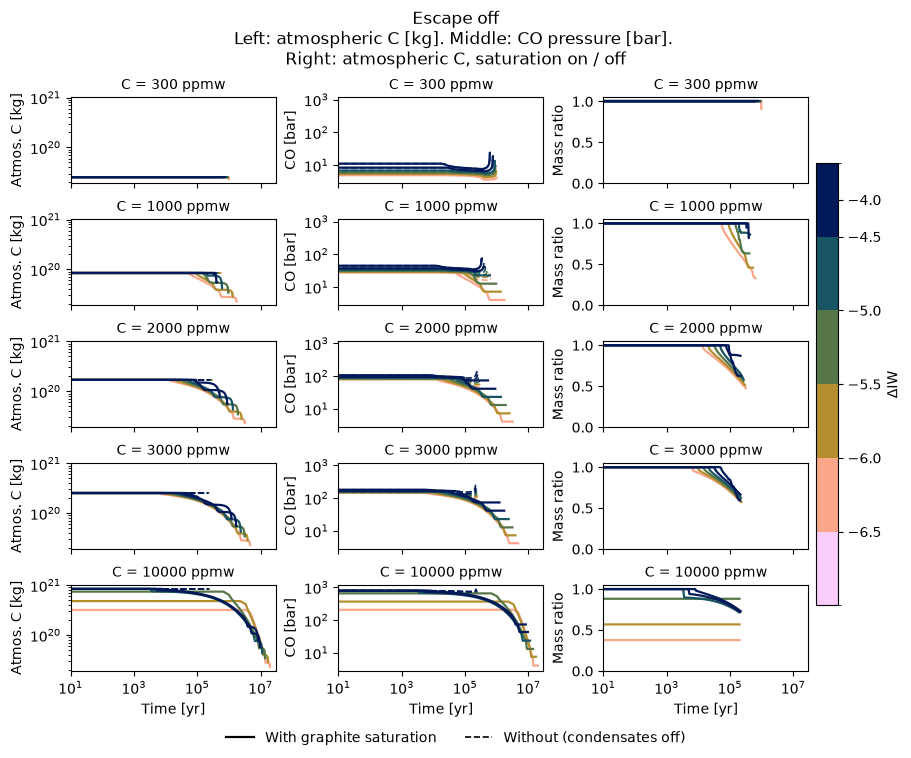

Escape on ($\eta$ = 0.1): 30 grid points have both saturation runs completed


/tmp/ipykernel_2544855/2615890507.py:12: RuntimeWarning: divide by zero encountered in log10
  c_interp = 10 ** np.interp(np.log10(t_on[ok]), np.log10(t_off), np.log10(c_off))
/tmp/ipykernel_2544855/2615890507.py:13: RuntimeWarning: invalid value encountered in divide
  return t_on[ok], c_on[ok] / c_interp
/tmp/ipykernel_2544855/2615890507.py:13: RuntimeWarning: divide by zero encountered in divide
  return t_on[ok], c_on[ok] / c_interp


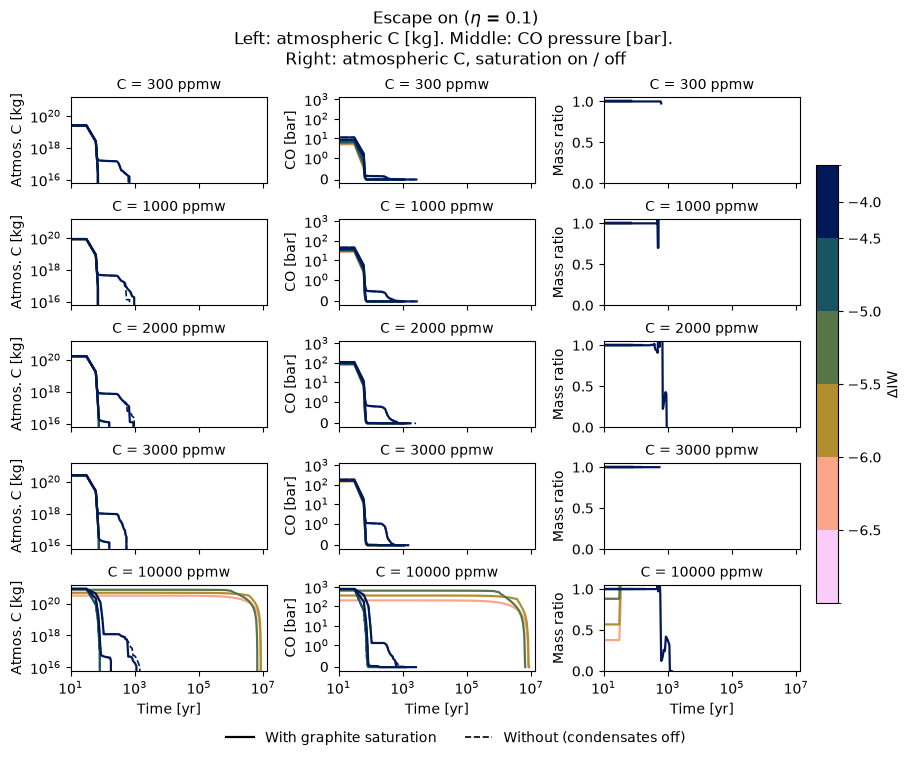

In [29]:
species = "CO"

def ratio_with_without(t_on, c_on, t_off, c_off):
    """Atmospheric C with condensates over that without, at the times of the run with them.

    The run without is interpolated in log-log onto those times, within the time range
    both runs cover.
    """
    keep = np.r_[np.diff(t_off) > 0, True] & (t_off > 0)
    t_off, c_off = t_off[keep], c_off[keep]
    ok = (t_on >= t_off[0]) & (t_on <= t_off[-1])
    c_interp = 10 ** np.interp(np.log10(t_on[ok]), np.log10(t_off), np.log10(c_off))
    return t_on[ok], c_on[ok] / c_interp

def plot_atm_carbon(e):
    """Atmospheric C, CO pressure and their with/without ratio for escape efficiency e."""
    pairs = {(x, c): (series[(x, c, True, e)], series[(x, c, False, e)])
             for (x, c, on, ee) in series if on and ee == e and (x, c, False, e) in series}
    print(f"{ESC_LABEL[e]}: {len(pairs)} grid points have both saturation runs completed")
    cmap = cmc.batlow_r
    norm = BoundaryNorm(np.concatenate([xs - 0.5, [xs[-1] + 0.5]]), cmap.N)

    nrow = len(ys)
    fig, axs = plt.subplots(nrow, 3, figsize=(9.0, 1.5 * nrow), sharex=True, sharey="col",
                            squeeze=False, layout="constrained")
    for (ax_l, ax_m, ax_r), c in zip(axs, ys):
        for x in xs:
            if (x, c) not in pairs:
                continue
            col = cmap(norm(x))
            r1, r0 = pairs[(x, c)]
            t1, t0 = r1["Time"], r0["Time"]
            ax_l.plot(t1[t1 > 0], r1["C_kg_atm"][t1 > 0], color=col, lw=1.6)
            ax_l.plot(t0[t0 > 0], r0["C_kg_atm"][t0 > 0], color=col, lw=1.2, ls="--")
            ax_m.plot(t1[t1 > 0], r1[f"{species}_bar"][t1 > 0], color=col, lw=1.6)
            ax_m.plot(t0[t0 > 0], r0[f"{species}_bar"][t0 > 0], color=col, lw=1.2, ls="--")
            ax_r.plot(*ratio_with_without(t1, r1["C_kg_atm"], t0, r0["C_kg_atm"]), color=col, lw=1.6)
        ax_l.set_yscale("log")
        ax_m.set_yscale("symlog", linthresh=1)
        ax_r.set_ylim(0, 1.05)
        for ax in (ax_l, ax_m, ax_r):
            ax.set_xscale("log")
            ax.set_title(f"C = {c:.0f} ppmw", fontsize=10)
        ax_l.set_ylabel("Atmos. C [kg]")
        ax_m.set_ylabel(f"{species} [bar]")
        ax_r.set_ylabel("Mass ratio")
    t_max = max(r[k]["Time"][-1] for r in pairs.values() for k in (0, 1))
    axs[0, 0].set_xlim(10, 1.5 * t_max)   # once, after plotting: per-axis calls freeze the right limit
    for ax in axs[-1]:
        ax.set_xlabel("Time [yr]")

    fig.suptitle(f"{ESC_LABEL[e]}\nLeft: atmospheric C [kg]. Middle: {species} pressure [bar]. \n"
                 "Right: atmospheric C, saturation on / off")
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    fig.colorbar(sm, ax=axs, ticks=xs, pad=0.01, fraction=0.03).set_label(r"$\Delta$IW")
    styles = [Line2D([], [], color="k", lw=1.6), Line2D([], [], color="k", lw=1.2, ls="--")]
    fig.legend(styles, ["With graphite saturation", "Without (condensates off)"],
               loc="outside lower center", ncol=2, frameon=False)
    fig.savefig(os.path.join(outdir, f"atm_carbon_with_without_graphite_eta{e:g}.pdf"),
                bbox_inches="tight")
    plt.show()

    # Endpoint of each run: atmospheric C with and without graphite, and the graphite held
    return pd.DataFrame([dict(eta=e, dIW=x, C=c,
                              C_atm_with=r1["C_kg_atm"][-1], C_atm_without=r0["C_kg_atm"][-1],
                              C_graphite=r1["C_kg_condensed"][-1],
                              t_end_with=r1["Time"][-1], t_end_without=r0["Time"][-1])
                         for (x, c), (r1, r0) in sorted(pairs.items())])

end = pd.concat([plot_atm_carbon(e) for e in ESC_ARMS], ignore_index=True)
end["ratio"] = end["C_atm_with"] / end["C_atm_without"]
end.to_csv(os.path.join(outdir, "atm_carbon_with_without_graphite.csv"), index=False)
# end

## Thermal effect of the graphite skin

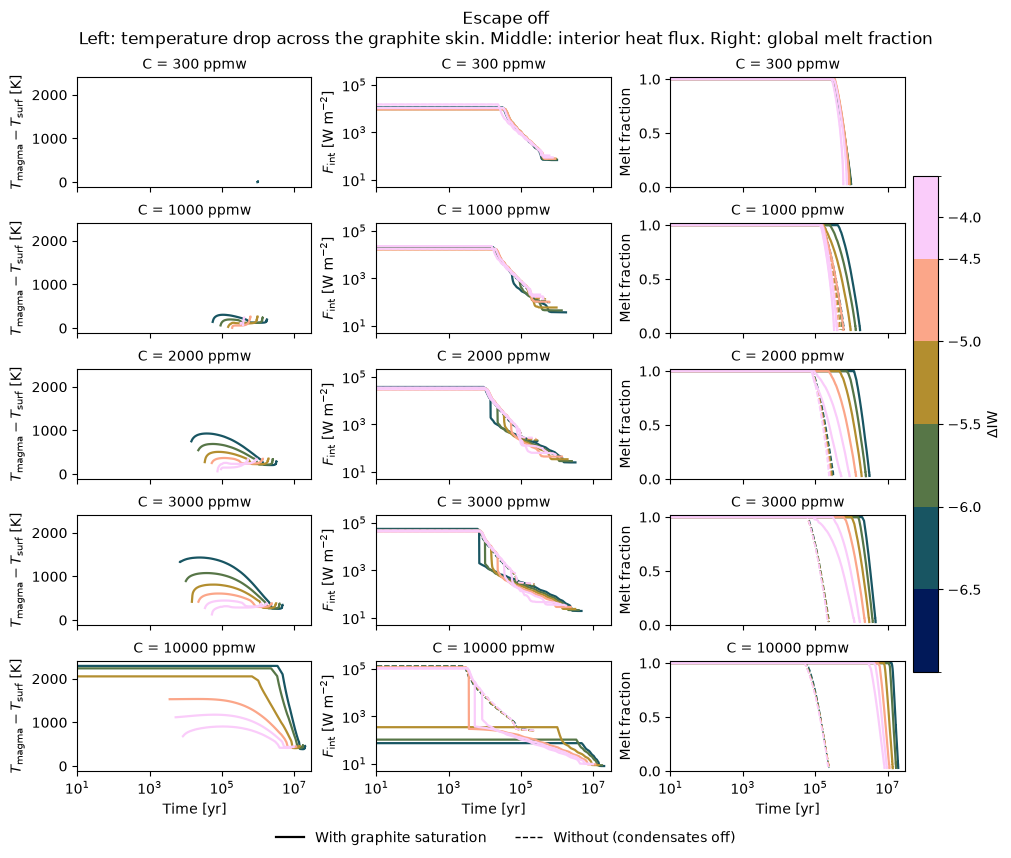

In [10]:
cmap_f = cmc.batlow
norm_f = BoundaryNorm(np.concatenate([xs - 0.5, [xs[-1] + 0.5]]), cmap_f.N)

def plot_skin_thermal(e):
    """Skin temperature drop, interior flux and melt fraction against time, escape efficiency e."""
    nrow = len(ys)
    fig, axs = plt.subplots(nrow, 3, figsize=(10.0, 1.7 * nrow), sharex=True, sharey="col",
                            squeeze=False, layout="constrained")
    for (ax_d, ax_f, ax_p), c in zip(axs, ys):
        for x in xs:
            if (x, c, True, e) not in series:
                continue
            col = cmap_f(norm_f(x))
            r1 = series[(x, c, True, e)]
            ok = r1["Time"] > 0
            skin = ok & (r1["boundary_layer_thickness"] > 0)
            if skin.any():
                ax_d.plot(r1["Time"][skin], r1["dT_skin"][skin], color=col, lw=1.6)
            ax_f.plot(r1["Time"][ok], r1["F_int"][ok], color=col, lw=1.6)
            ax_p.plot(r1["Time"][ok], r1["Phi_global"][ok], color=col, lw=1.6)
            if (x, c, False, e) in series:
                r0 = series[(x, c, False, e)]
                ok0 = r0["Time"] > 0
                ax_f.plot(r0["Time"][ok0], r0["F_int"][ok0], color=col, lw=1.0, ls="--")
                ax_p.plot(r0["Time"][ok0], r0["Phi_global"][ok0], color=col, lw=1.0, ls="--")
        ax_f.set_yscale("log")
        ax_p.set_ylim(0, 1.02)
        for ax in (ax_d, ax_f, ax_p):
            ax.set_xscale("log")
            ax.set_title(f"C = {c:.0f} ppmw", fontsize=10)
        ax_d.set_ylabel(r"$T_\mathrm{magma} - T_\mathrm{surf}$ [K]")
        ax_f.set_ylabel(r"$F_\mathrm{int}$ [W m$^{-2}$]")
        ax_p.set_ylabel("Melt fraction")
    t_max = max(ts["Time"][-1] for (x, c, on, ee), ts in series.items() if ee == e)
    axs[0, 0].set_xlim(10, 1.5 * t_max)   # once, after plotting: per-axis calls freeze the right limit
    for ax in axs[-1]:
        ax.set_xlabel("Time [yr]")

    fig.suptitle(f"{ESC_LABEL[e]}\nLeft: temperature drop across the graphite skin. "
                 "Middle: interior heat flux. Right: global melt fraction")
    sm = plt.cm.ScalarMappable(cmap=cmap_f, norm=norm_f)
    fig.colorbar(sm, ax=axs, ticks=xs, pad=0.01, fraction=0.03).set_label(r"$\Delta$IW")
    styles = [Line2D([], [], color="k", lw=1.6), Line2D([], [], color="k", lw=1.0, ls="--")]
    fig.legend(styles, ["With graphite saturation", "Without (condensates off)"],
               loc="outside lower center", ncol=2, frameon=False)
    fig.savefig(os.path.join(outdir, f"skin_thermal_vs_time_eta{e:g}.pdf"), bbox_inches="tight")
    plt.show()

plot_skin_thermal(ETA_OFF)

### Skin temperature drop and solidification time across the grid

Escape off. Left and middle: the largest and the final $\Delta T$ across the skin in the saturation-on runs. Right: the end time of the saturation-on run over that of the saturation-off run at the same grid point. Every escape-off run stopped at solidification, so the ratio is the change in solidification time; a `*` would mark a run that stopped for another reason. With escape on the runs stop for different reasons, so this ratio is not shown for them.

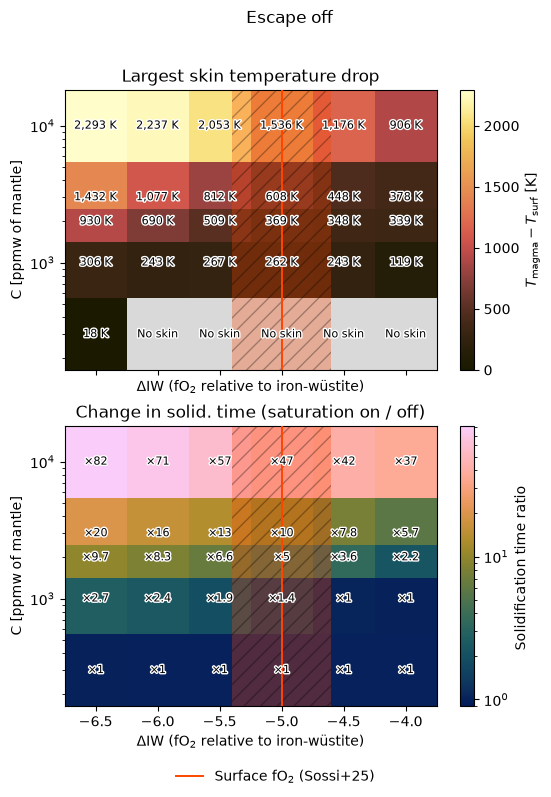

In [30]:
on, off = arm(True, ETA_OFF), arm(False, ETA_OFF)
Z_dTmax = on_plane("dT_skin_max", on)
Z_ratio = on_plane("time_end", on) / on_plane("time_end", off)
Z_stat = np.maximum(on_plane("status", on), on_plane("status", off))
nonsolid = lambda i, j: "" if Z_stat[i, j] == 10 else "*"

no_skin = Z_dTmax <= 0
norm_dT = Normalize(vmin=0, vmax=np.nanmax(Z_dTmax))
r_lo, r_hi = np.nanmin(Z_ratio), np.nanmax(Z_ratio)
norm_r = LogNorm(vmin=min(r_lo, 0.9), vmax=max(r_hi, 1.1))

fig, axs = plt.subplots(2,1, figsize=(6,8), sharex=True)

pm = mesh(axs[0], Z_dTmax, cmc.lajolla, norm_dT, lambda i, j: f"{Z_dTmax[i, j]:,.0f} K", no_skin, "No skin")
fig.colorbar(pm, ax=axs[0], label=r"$T_\mathrm{magma} - T_\mathrm{surf}$ [K]")

cmap = deepcopy(cmc.batlow)
cmap.set_under("white")
pm = mesh(axs[1], Z_ratio, cmap, norm_r, lambda i, j: f"×{Z_ratio[i, j]:.2g}{nonsolid(i, j)}",
          np.zeros_like(no_skin), "")
fig.colorbar(pm, ax=axs[-1], label="Solidification time ratio ")

axs[0].set_title("Largest skin temperature drop")
axs[1].set_title("Change in solid. time (saturation on / off)")
for ax in axs:
    plane_axes(ax, legend=(ax is axs[0]))
fig.suptitle(ESC_LABEL[ETA_OFF])
fig.legend(loc="outside lower center", frameon=False)
fig.savefig(os.path.join(outdir, "skin_thermal_grid.pdf"), bbox_inches="tight")
plt.show()